# GR5398 26 Spring: FinRL-Trading Quantitative Trading Strategy Track
## Assignment 1

### 1. Data Preprocessing

In [1]:
import os
import pandas as pd
import numpy as np
import warnings
from datetime import datetime as dt
import sys
import time
from pathlib import Path
import yfinance as yf
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

warnings.filterwarnings("ignore")

In [ ]:
def load_data(fundamental_file, price_file):
    print("Loading data files...")
    
    if not os.path.isfile(fundamental_file):
        raise FileNotFoundError(f"Fundamental file {fundamental_file} not found.")
    
    if not os.path.isfile(price_file):
        raise FileNotFoundError(f"Price file {price_file} not found.")
    
    fund_df = pd.read_csv(fundamental_file)
    print(fund_df.head())
    
    print("Loading price data (only necessary columns)...")
    price_columns = ['gvkey', 'tic', 'datadate', 'prccd', 'ajexdi']
    df_daily_price = pd.read_csv(price_file, usecols=price_columns)
    print(df_daily_price.head())
    
    print(f"Fundamental data shape: {fund_df.shape}")
    print(f"Price data shape: {df_daily_price.shape}")
    print(f"Unique tickers in fundamental data: {len(fund_df.tic.unique())}")
    print(f"Unique tickers in price data: {len(df_daily_price.tic.unique())}")
    
    return fund_df, df_daily_price

In [ ]:
def adjust_trade_dates(fund_df):
    print("Adjusting trade dates...")
    
    datadate_dt = pd.to_datetime(fund_df['datadate'])

    fund_df['tradedate'] = ((datadate_dt.dt.to_period('Q')).dt.end_time.dt.normalize())
    fund_df['reportdate'] = fund_df["rdq"]
    
    return fund_df

In [ ]:
def calculate_adjusted_close(fund_df):
    print("Calculating adjusted close price...")
    fund_df['adj_close_q'] = fund_df.prccq / fund_df.adjex
    return fund_df

In [ ]:
def match_tickers_and_gvkey(fund_df, df_daily_price):
    print("Matching tickers and gvkey...")
    
    tic_to_gvkey = {}
    df_daily_groups = list(df_daily_price.groupby('tic'))
    
    for tic, df_ in df_daily_groups:
        tic_to_gvkey[tic] = df_.gvkey.iloc[0]
    
    print(f"Original fundamental data shape: {fund_df.shape}")
    
    fund_df = fund_df[np.isin(fund_df.tic, list(tic_to_gvkey.keys()))]
    
    print(f"Filtered fundamental data shape: {fund_df.shape}")
    print(f"Unique gvkeys: {len(fund_df.gvkey.unique())}")
    
    fund_df['gvkey'] = [tic_to_gvkey[x] for x in fund_df['tic']]
    
    return fund_df

In [ ]:
def calculate_next_quarter_returns(fund_df):
    print("Calculating next quarter returns...")
    
    fund_df['date'] = fund_df["tradedate"]
    # fund_df['date'] = pd.to_datetime(fund_df['date'], format="%Y-%m%d")
    fund_df['date'] = pd.to_datetime(fund_df['date'])
    fund_df.drop_duplicates(["date", "gvkey"], keep='last', inplace=True)
    
    l_df = list(fund_df.groupby('gvkey'))
    for tic, df in l_df:
        df.reset_index(inplace=True, drop=True)
        df = df.sort_values('date')
        df['y_return'] = np.log(df['adj_close_q'].shift(-1) / df['adj_close_q'])
    
    fund_df = pd.concat([x[1] for x in l_df])
    
    print(f"Data shape after calculating returns: {fund_df.shape}")
    return fund_df

In [ ]:
def calculate_basic_ratios(fund_df):
    print("Calculating basic financial ratios...")
    
    fund_df['pe'] = fund_df.prccq / fund_df.epspxq
    fund_df['ps'] = fund_df.prccq / (fund_df.revtq / fund_df.cshoq)
    fund_df['pb'] = fund_df.prccq / ((fund_df.atq - fund_df.ltq) / fund_df.cshoq)
    
    return fund_df

In [ ]:
def select_columns(fund_df):
    print("Selecting relevant columns...")
    
    items = [
        'date', 'gvkey', 'tic', 'gsector',
        'oiadpq', 'revtq', 'niq', 'atq', 'teqq', 'epspiy', 'ceqq', 'cshoq', 'dvpspq',
        'actq', 'lctq', 'cheq', 'rectq', 'cogsq', 'invtq', 'apq', 'dlttq', 'dlcq', 'ltq',
        'pe', 'ps', 'pb', 'adj_close_q', 'y_return', 'reportdate'
    ]
    
    fund_data = fund_df[items]
    
    # Rename columns for readability
    fund_data = fund_data.rename(columns={
        'oiadpq': 'op_inc_q',
        'revtq': 'rev_q',
        'niq': 'net_inc_q',
        'atq': 'tot_assets',
        'teqq': 'sh_equity',
        'epspiy': 'eps_incl_ex',
        'ceqq': 'com_eq',
        'cshoq': 'sh_outstanding',
        'dvpspq': 'div_per_sh',
        'actq': 'cur_assets',
        'lctq': 'cur_liabilities',
        'cheq': 'cash_eq',
        'rectq': 'receivables',
        'cogsq': 'cogs_q',
        'invtq': 'inventories',
        'apq': 'payables',
        'dlttq': 'long_debt',
        'dlcq': 'short_debt',
        'ltq': 'tot_liabilities'
    })
    
    return fund_data

In [ ]:
def calculate_financial_ratios(fund_data):
    print("Calculating comprehensive financial ratios...")
    
    date = fund_data['date'].to_frame('date').reset_index(drop=True)
    reportdate = fund_data['reportdate'].to_frame('reportdate').reset_index(drop=True)
    tic = fund_data['tic'].to_frame('tic').reset_index(drop=True)
    gvkey = fund_data['gvkey'].to_frame('gvkey').reset_index(drop=True)
    adj_close_q = fund_data['adj_close_q'].to_frame('adj_close_q').reset_index(drop=True)
    y_return = fund_data['y_return'].to_frame('y_return').reset_index(drop=True)
    gsector = fund_data['gsector'].to_frame('gsector').reset_index(drop=True)
    pe = fund_data['pe'].to_frame('pe').reset_index(drop=True)
    ps = fund_data['ps'].to_frame('ps').reset_index(drop=True)
    pb = fund_data['pb'].to_frame('pb').reset_index(drop=True)
    
    print("Calculating profitability ratios...")
    
    OPM = pd.Series(np.empty(fund_data.shape[0], dtype=object), name='OPM')
    for i in range(0, fund_data.shape[0]):
        if i-3 < 0:
            OPM[i] = np.nan
        elif fund_data.iloc[i, 1] != fund_data.iloc[i-3, 1]:
            OPM.iloc[i] = np.nan
        else:
            OPM.iloc[i] = np.sum(fund_data['op_inc_q'].iloc[i-3:i]) / np.sum(fund_data['rev_q'].iloc[i-3:i])
    OPM = pd.Series(OPM).to_frame().reset_index(drop=True)
    
    NPM = pd.Series(np.empty(fund_data.shape[0], dtype=object), name='NPM')
    for i in range(0, fund_data.shape[0]):
        if i-3 < 0:
            NPM[i] = np.nan
        elif fund_data.iloc[i, 1] != fund_data.iloc[i-3, 1]:
            NPM.iloc[i] = np.nan
        else:
            NPM.iloc[i] = np.sum(fund_data['net_inc_q'].iloc[i-3:i]) / np.sum(fund_data['rev_q'].iloc[i-3:i])
    NPM = pd.Series(NPM).to_frame().reset_index(drop=True)
    
    ROA = pd.Series(np.empty(fund_data.shape[0], dtype=object), name='ROA')
    for i in range(0, fund_data.shape[0]):
        if i-3 < 0:
            ROA[i] = np.nan
        elif fund_data.iloc[i, 1] != fund_data.iloc[i-3, 1]:
            ROA.iloc[i] = np.nan
        else:
            ROA.iloc[i] = np.sum(fund_data['net_inc_q'].iloc[i-3:i]) / fund_data['tot_assets'].iloc[i]
    ROA = pd.Series(ROA).to_frame().reset_index(drop=True)
    
    ROE = pd.Series(np.empty(fund_data.shape[0], dtype=object), name='ROE')
    for i in range(0, fund_data.shape[0]):
        if i-3 < 0:
            ROE[i] = np.nan
        elif fund_data.iloc[i, 1] != fund_data.iloc[i-3, 1]:
            ROE.iloc[i] = np.nan
        else:
            ROE.iloc[i] = np.sum(fund_data['net_inc_q'].iloc[i-3:i]) / fund_data['sh_equity'].iloc[i]
    ROE = pd.Series(ROE).to_frame().reset_index(drop=True)
    
    EPS = fund_data['eps_incl_ex'].to_frame('EPS').reset_index(drop=True)
    BPS = (fund_data['com_eq'] / fund_data['sh_outstanding']).to_frame('BPS').reset_index(drop=True)
    DPS = fund_data['div_per_sh'].to_frame('DPS').reset_index(drop=True)
    
    print("  Calculating liquidity ratios...")
    cur_ratio = (fund_data['cur_assets'] / fund_data['cur_liabilities']).to_frame('cur_ratio').reset_index(drop=True)
    quick_ratio = ((fund_data['cash_eq'] + fund_data['receivables']) / fund_data['cur_liabilities']).to_frame('quick_ratio').reset_index(drop=True)
    cash_ratio = (fund_data['cash_eq'] / fund_data['cur_liabilities']).to_frame('cash_ratio').reset_index(drop=True)
    
    print("  Calculating efficiency ratios...")
    
    inv_turnover = pd.Series(np.empty(fund_data.shape[0], dtype=object), name='inv_turnover')
    for i in range(0, fund_data.shape[0]):
        if i-3 < 0:
            inv_turnover[i] = np.nan
        elif fund_data.iloc[i, 1] != fund_data.iloc[i-3, 1]:
            inv_turnover.iloc[i] = np.nan
        else:
            inv_turnover.iloc[i] = np.sum(fund_data['cogs_q'].iloc[i-3:i]) / fund_data['inventories'].iloc[i]
    inv_turnover = pd.Series(inv_turnover).to_frame().reset_index(drop=True)
    
    acc_rec_turnover = pd.Series(np.empty(fund_data.shape[0], dtype=object), name='acc_rec_turnover')
    for i in range(0, fund_data.shape[0]):
        if i-3 < 0:
            acc_rec_turnover[i] = np.nan
        elif fund_data.iloc[i, 1] != fund_data.iloc[i-3, 1]:
            acc_rec_turnover.iloc[i] = np.nan
        else:
            acc_rec_turnover.iloc[i] = np.sum(fund_data['rev_q'].iloc[i-3:i]) / fund_data['receivables'].iloc[i]
    acc_rec_turnover = pd.Series(acc_rec_turnover).to_frame().reset_index(drop=True)
    
    acc_pay_turnover = pd.Series(np.empty(fund_data.shape[0], dtype=object), name='acc_pay_turnover')
    for i in range(0, fund_data.shape[0]):
        if i-3 < 0:
            acc_pay_turnover[i] = np.nan
        elif fund_data.iloc[i, 1] != fund_data.iloc[i-3, 1]:
            acc_pay_turnover.iloc[i] = np.nan
        else:
            acc_pay_turnover.iloc[i] = np.sum(fund_data['cogs_q'].iloc[i-3:i]) / fund_data['payables'].iloc[i]
    acc_pay_turnover = pd.Series(acc_pay_turnover).to_frame().reset_index(drop=True)
    
    print("  Calculating leverage ratios...")
    debt_ratio = (fund_data['tot_liabilities'] / fund_data['tot_assets']).to_frame('debt_ratio').reset_index(drop=True)
    debt_to_equity = (fund_data['tot_liabilities'] / fund_data['sh_equity']).to_frame('debt_to_equity').reset_index(drop=True)
    
    ratios = pd.concat([
        date, gvkey, tic, gsector, adj_close_q, y_return,
        OPM, NPM, ROA, ROE, EPS, BPS, DPS,
        cur_ratio, quick_ratio, cash_ratio, inv_turnover, acc_rec_turnover, acc_pay_turnover,
        debt_ratio, debt_to_equity, pe, ps, pb, reportdate
    ], axis=1).reset_index(drop=True)
    
    return ratios

In [ ]:
def handle_missing_values(ratios):
    print("Handling missing values...")
    
    # Replace NAs and infinite values with zero initially
    final_ratios = ratios.copy()
    final_ratios = final_ratios.fillna(0)
    final_ratios = final_ratios.replace(np.inf, 0)
    
    features_column_financial = [
        'OPM', 'NPM', 'ROA', 'ROE', 'EPS', 'BPS', 'DPS', 'cur_ratio',
        'quick_ratio', 'cash_ratio', 'inv_turnover', 'acc_rec_turnover',
        'acc_pay_turnover', 'debt_ratio', 'debt_to_equity', 'pe', 'ps', 'pb'
    ]
    
    final_ratios = final_ratios.drop(list(final_ratios[final_ratios.adj_close_q == 0].index)).reset_index(drop=True)
    
    final_ratios['y_return'] = pd.to_numeric(final_ratios['y_return'], errors='coerce')
    for col in features_column_financial:
        if col in final_ratios.columns:
            final_ratios[col] = pd.to_numeric(final_ratios[col], errors='coerce')
    
    final_ratios['y_return'].replace([np.nan, np.inf, -np.inf], np.nan, inplace=True)
    final_ratios[features_column_financial].replace([np.nan, np.inf, -np.inf], np.nan, inplace=True)
    
    dropped_col = []
    for col in features_column_financial:
        if col in final_ratios.columns and np.any(~np.isfinite(final_ratios[col])):
            final_ratios.drop(columns=[col], axis=1, inplace=True)
            dropped_col.append(col)
    
    final_ratios.dropna(axis=0, inplace=True)
    final_ratios = final_ratios[final_ratios["reportdate"].ne(0)]  
    final_ratios = final_ratios.reset_index(drop=True)
    
    print(f"Dropped columns: {dropped_col}")
    print(f"Final data shape: {final_ratios.shape}")
    
    return final_ratios

In [ ]:
def save_results(final_ratios, output_dir="outputs", include_sector0=False):
    print("Saving results...")
    
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
    
    main_output_file = os.path.join(output_dir, 'final_ratios.csv')
    final_ratios.to_csv(main_output_file, index=False)
    print(f"Main results saved to: {main_output_file}")
    
    print("Saving sector-specific files...")
    sector_count = 0
    for sec, df_ in list(final_ratios.groupby('gsector')):
        if sec == 0 and not include_sector0:
            print(f"  Skipping Sector 0: {len(df_)} records (stocks with missing sector information)")
            continue
        
        sector_file = os.path.join(output_dir, f"sector{int(sec)}.xlsx")
        df_.to_excel(sector_file, index=False)
        print(f"  Sector {int(sec)}: {sector_file} ({len(df_)} records)")
        sector_count += 1
    
    print(f"  Total sectors saved: {sector_count}")
    
    return main_output_file

In [ ]:
Stock_Index_price_file = "./prepared/daily.csv" 
output_dir = "./prepared"                         
include_sector0 = False


### 2. Stock Selection

In [ ]:
def create_directory_if_not_exists(directory_path):
    path = Path(directory_path)
    if not path.exists():
        path.mkdir(parents=True, exist_ok=True)
        print(f"✓ Created directory: {directory_path}")
    else:
        print(f"✓ Directory already exists: {directory_path}")

def quarter_ffill(df: pd.DataFrame) -> pd.DataFrame:
    qkey = df.index.to_period("Q")
    df = df.groupby(qkey).ffill()
    return df

def quarter_reportday_ffill(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.index = pd.to_datetime(df.index)

    full_idx = pd.bdate_range(df.index.min(), df.index.max())

    out = df.reindex(full_idx)
    out = out.sort_index().copy()
    idx = out.index
    for col in out.columns:
        s = out[col]
        if not s.notna().any():
            continue
        dates = s.dropna().index
        for i, t0 in enumerate(dates):
            val = s.at[t0]
            t1 = dates[i + 1] if i + 1 < len(dates) else None
            cap = (t0.to_period('Q') + 1).end_time.normalize()
            mask = (idx > t0) & (idx < (t1 if t1 and t1 <= cap else cap + pd.Timedelta('1ns')))
            out.loc[mask, col] = val
    return out

In [ ]:
def run_stock_selection(data_path, output_path):
    sectors = range(10, 65, 5)
    
    DATA_DIR = data_path
    FUNDAMENTAL_FILE = os.path.join(DATA_DIR, "final_ratios.csv")
    
    print(f"Using data directory: {DATA_DIR}")
    print(f"Fundamental data file: {FUNDAMENTAL_FILE}")
    print(f"Output directory: {output_path}")
    print(f"Sector range: {list(sectors)}")
    
    if not os.path.exists(FUNDAMENTAL_FILE):
        print(f"Error: Fundamental data file does not exist: {FUNDAMENTAL_FILE}")
        sys.exit(1)
    
    create_directory_if_not_exists(output_path)
    
    df_dict = {'tic': [], 'predicted_return': [], 'trade_date': []}
    
    start = time.time()
    print("\nStarting stock selection model for all sectors...")

    df_all = pd.DataFrame()
    
    for sector in sectors:
        sector_file = os.path.join(DATA_DIR, f"sector{sector}.xlsx")
        print(f"\nProcessing sector{sector}...")
        
        if not os.path.exists(sector_file):
            print(f"   Warning: Sector file does not exist, skipping: {sector_file}")
            continue
        
        cmd = f"{sys.executable} fundamental_run_model.py -sector_name sector{sector} -tic_column tic -fundamental {FUNDAMENTAL_FILE} -sector {sector_file}"
        print(f"Executing command: {cmd}")
        
        result = os.system(cmd)
        if result != 0:
            print(f" sector{sector} model training failed")
            continue
        
        result_file = f"results/sector{sector}/df_predict_best.csv"
        if not os.path.exists(result_file):
            print(f" Prediction result file does not exist: {result_file}")
            continue

        df = pd.read_csv(result_file, index_col=0)
        df.index = pd.to_datetime(df.index)
        print(f"  Reading prediction results: {df.shape[0]} dates, {df.shape[1]} stocks")
        df = quarter_reportday_ffill(df)
        df_all = pd.concat([df_all, df], axis=1)
        print(f" sector{sector} processing completed")

    for idx in df_all.index:
        predicted_return = df_all.loc[idx]
        btm_q = predicted_return.quantile(0.75)
        predicted_return = predicted_return[predicted_return >= btm_q]
        for tic in predicted_return.index:
            df_dict["tic"].append(tic)
            df_dict["predicted_return"].append(predicted_return[tic])
            df_dict["trade_date"].append(idx)
    
    end = time.time()
    
    print(f"\nTotal time: {(end-start)/60:.2f} minutes")
    print(f"Processing completed! Total records: {len(df_dict['tic'])}")
    
    df_result = pd.DataFrame(df_dict)
    
    output_file = os.path.join(output_path, "stock_selected.csv")
    df_result.to_csv(output_file, index=False)
    print(f"Results saved to: {output_file}")
    
    if len(df_result) > 0:
        print(f"\nResult statistics:")
        print(f"  Total records: {len(df_result)}")
        print(f"  Unique stocks: {df_result['tic'].nunique()}")
        print(f"  Date range: {df_result['trade_date'].min()} to {df_result['trade_date'].max()}")
        print(f"  Predicted return range: {df_result['predicted_return'].min():.4f} to {df_result['predicted_return'].max():.4f}")
    else:
        print("\nWarning: No stock selection results generated")

In [ ]:
data_path = "./prepared"  
output_path_step2 = "./outputs"


In [16]:
run_stock_selection(data_path, output_path_step2)

Using data directory: ./prepared
Fundamental data file: ./prepared/final_ratios.csv
Output directory: ./outputs
Sector range: [10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60]
✓ Directory already exists: ./outputs

Starting stock selection model for all sectors...

Processing sector10...
Executing command: /opt/anaconda3/bin/python fundamental_run_model.py -sector_name sector10 -tic_column tic -fundamental ./prepared/final_ratios.csv -sector ./prepared/sector10.xlsx


xgb:11.231154s
gbm:1.242230s
rf:2.609953s
Trade Date:  2020-06-30 00:00:00
xgb:9.013372s
gbm:1.097673s
rf:2.454325s
Trade Date:  2020-09-30 00:00:00
xgb:9.383033s
gbm:1.251097s
rf:2.461769s
Trade Date:  2020-12-31 00:00:00
xgb:9.210171s
gbm:1.161705s
rf:2.430700s
Trade Date:  2021-03-31 00:00:00
xgb:11.212605s
gbm:1.261753s
rf:2.386839s
Trade Date:  2021-06-30 00:00:00
xgb:11.026742s
gbm:1.431181s
rf:2.488359s
Trade Date:  2021-09-30 00:00:00
xgb:11.491819s
gbm:2.135613s
rf:2.449837s
Trade Date:  2021-12-31 00:00:00
xgb:12.813207s
gbm:2.268137s
rf:2.651545s
Trade Date:  2022-03-31 00:00:00
xgb:11.833609s
gbm:2.015831s
rf:2.586379s
Trade Date:  2022-06-30 00:00:00
xgb:11.169551s
gbm:2.531640s
rf:2.601053s
Trade Date:  2022-09-30 00:00:00
xgb:11.656747s
gbm:2.230420s
rf:2.665316s
Trade Date:  2022-12-31 00:00:00
xgb:12.671129s
gbm:2.464390s
rf:2.577536s
Trade Date:  2023-03-31 00:00:00
xgb:11.304706s
gbm:2.477946s
rf:2.711123s
Trade Date:  2023-06-30 00:00:00
xgb:11.671394s
gbm:2.670597s

Exception ignored in: <function ResourceTracker.__del__ at 0x1079adbc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x107219bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x10398dbc0>
Traceback (most recent call last

  Reading prediction results: 232 dates, 41 stocks
 sector10 processing completed

Processing sector15...
Executing command: /opt/anaconda3/bin/python fundamental_run_model.py -sector_name sector15 -tic_column tic -fundamental ./prepared/final_ratios.csv -sector ./prepared/sector15.xlsx


xgb:7.069375s
gbm:0.440290s
rf:2.389495s
Trade Date:  2020-09-30 00:00:00
xgb:5.821239s
gbm:0.443391s
rf:2.170035s
Trade Date:  2020-12-31 00:00:00
xgb:5.984896s
gbm:0.540613s
rf:2.178952s
Trade Date:  2021-03-31 00:00:00
xgb:5.546790s
gbm:0.777177s
rf:2.237377s
Trade Date:  2021-06-30 00:00:00
xgb:6.010347s
gbm:0.845231s
rf:2.208681s
Trade Date:  2021-09-30 00:00:00
xgb:6.172715s
gbm:0.645289s
rf:2.399763s
Trade Date:  2021-12-31 00:00:00
xgb:6.389663s
gbm:0.723598s
rf:2.320893s
Trade Date:  2022-03-31 00:00:00
xgb:7.181971s
gbm:1.121660s
rf:2.246717s
Trade Date:  2022-06-30 00:00:00
xgb:6.737732s
gbm:1.036938s
rf:2.411457s
Trade Date:  2022-09-30 00:00:00
xgb:7.003085s
gbm:1.151422s
rf:2.310788s
Trade Date:  2022-12-31 00:00:00
xgb:8.042999s
gbm:1.093879s
rf:2.389747s
Trade Date:  2023-03-31 00:00:00
xgb:8.364630s
gbm:1.093270s
rf:2.433861s
Trade Date:  2023-06-30 00:00:00
xgb:8.448382s
gbm:1.265449s
rf:2.457372s
Trade Date:  2023-09-30 00:00:00
xgb:8.248120s
gbm:1.243144s
rf:2.48790

...

gbm:4.081772s
rf:2.923963s
Trade Date:  2025-09-30 00:00:00
Time Spent: 5.280109 minutes


Exception ignored in: <function ResourceTracker.__del__ at 0x10998dbc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x107f15bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x10458dbc0>
Traceback (most recent call last

  Reading prediction results: 255 dates, 37 stocks
 sector60 processing completed



Total time: 68.82 minutes
Processing completed! Total records: 174002


Results saved to: ./outputs/stock_selected.csv

Result statistics:
  Total records: 174002
  Unique stocks: 419
  Date range: 2020-05-01 00:00:00 to 2025-11-25 00:00:00
  Predicted return range: 0.0157 to 0.1794


### 3. Backtest

In [ ]:
print("=" * 80)
print("Equal Weight Portfolio Construction")
print("=" * 80)

selected_stocks_df = pd.read_csv(os.path.join(output_path_step2, "stock_selected.csv"))
selected_stocks_df['trade_date'] = pd.to_datetime(selected_stocks_df['trade_date'])

print(f"\nSelected stocks data shape: {selected_stocks_df.shape}")
print(f"Date range: {selected_stocks_df['trade_date'].min()} to {selected_stocks_df['trade_date'].max()}")
print(f"Unique stocks: {selected_stocks_df['tic'].nunique()}")
print(f"\nStock list: {sorted(selected_stocks_df['tic'].unique())}")

price_columns = ['tic', 'datadate', 'prccd']
df_daily_price = pd.read_csv(Stock_Index_price_file, usecols=price_columns)
df_daily_price['datadate'] = pd.to_datetime(df_daily_price['datadate'])
df_daily_price = df_daily_price.rename(columns={'prccd': 'close'})

print(f"\nDaily price data shape: {df_daily_price.shape}")
print(f"Price date range: {df_daily_price['datadate'].min()} to {df_daily_price['datadate'].max()}")

portfolio_dates = sorted(selected_stocks_df['trade_date'].unique())
all_stocks_in_portfolio = sorted(selected_stocks_df['tic'].unique())

print(f"\nPortfolio dates: {len(portfolio_dates)}")
print(f"All stocks in portfolio: {len(all_stocks_in_portfolio)}")

portfolio_weights_dict = {}

for date in portfolio_dates:
    stocks_on_date = selected_stocks_df[selected_stocks_df['trade_date'] == date]['tic'].unique()
    n_stocks = len(stocks_on_date)
    
    portfolio_weights_dict[date] = {}
    for stock in all_stocks_in_portfolio:
        if stock in stocks_on_date:
            portfolio_weights_dict[date][stock] = 1.0 / n_stocks
        else:
            portfolio_weights_dict[date][stock] = 0.0

portfolio_weights_df = pd.DataFrame(portfolio_weights_dict).T
portfolio_weights_df.index.name = 'date'

print(f"\nPortfolio weights dataframe shape: {portfolio_weights_df.shape}")
print(f"Rows (dates): {portfolio_weights_df.shape[0]}, Columns (stocks): {portfolio_weights_df.shape[1]}")
print(f"\nFirst few dates and weights:")
print(portfolio_weights_df.head(10))
print(f"\nLast few dates and weights:")
print(portfolio_weights_df.tail(10))

weights_sum = portfolio_weights_df.sum(axis=1)
print(f"\nWeights sum check (should all be 1.0):")
print(f"  Min: {weights_sum.min():.6f}")
print(f"  Max: {weights_sum.max():.6f}")
print(f"  Mean: {weights_sum.mean():.6f}")

portfolio_weights_file = os.path.join(output_path_step2, "portfolio_weights.csv")
portfolio_weights_df.to_csv(portfolio_weights_file)
print(f"\n✓ Portfolio weights saved to: {portfolio_weights_file}")

print("\n" + "=" * 80)
print("Equal weight portfolio constructed successfully!")
print("=" * 80)

Equal Weight Portfolio Construction

Selected stocks data shape: (174002, 3)
Date range: 2020-05-01 00:00:00 to 2025-11-25 00:00:00
Unique stocks: 419

Stock list: ['A', 'AAL', 'AAPL', 'ABBV', 'ABC', 'ABMD', 'ABT', 'ACGL', 'ACN', 'ADBE', 'ADI', 'ADM', 'ADP', 'ADSK', 'AES', 'AFL', 'AIG', 'AIZ', 'AJG', 'AKAM', 'ALB', 'ALGN', 'ALK', 'ALL', 'ALLE', 'AMAT', 'AMD', 'AME', 'AMGN', 'AMP', 'AMTM', 'AMZN', 'ANET', 'ANSS', 'ANTM', 'AON', 'AOS', 'APD', 'APH', 'APP', 'ATVI', 'AVGO', 'AVY', 'AXON', 'AXP', 'BA', 'BAC', 'BALL', 'BAX', 'BBWI', 'BBY', 'BEN', 'BIO', 'BK', 'BLDR', 'BLK', 'BMY', 'BR', 'BRK.B', 'BRO', 'BSX', 'BWA', 'BX', 'C', 'CAH', 'CARR', 'CAT', 'CBOE', 'CBRE', 'CCL', 'CDAY', 'CDNS', 'CDW', 'CE', 'CEG', 'CERN', 'CF', 'CFG', 'CHRW', 'CI', 'CLX', 'CMA', 'CME', 'CMG', 'CMI', 'CNC', 'CNP', 'COF', 'COO', 'COR', 'COST', 'CPAY', 'CRL', 'CRM', 'CRWD', 'CSCO', 'CSX', 'CTAS', 'CTLT', 'CTSH', 'CTVA', 'CTXS', 'CVS', 'CVX', 'CXO', 'CZR', 'D', 'DAL', 'DAY', 'DD', 'DDOG', 'DE', 'DECK', 'DELL', 'DG', 'DG


Daily price data shape: (1261325, 3)
Price date range: 2015-06-15 00:00:00 to 2025-09-30 00:00:00

Portfolio dates: 1453
All stocks in portfolio: 419



Portfolio weights dataframe shape: (1453, 419)
Rows (dates): 1453, Columns (stocks): 419

First few dates and weights:
              A  AAL  AAPL  ABBV  ABC  ABMD  ABT  ACGL  ACN  ADBE  ...   WU  \
date                                                               ...        
2020-05-01  0.0  0.0   0.0   0.0  0.0   0.0  0.0   0.0  0.0   0.0  ...  0.0   
2020-05-04  0.0  0.0   0.0   0.0  0.0   0.0  0.0   0.0  0.0   0.0  ...  0.0   
2020-05-05  0.0  0.0   0.0   0.0  0.0   0.0  0.0   0.0  0.0   0.0  ...  0.0   
2020-05-06  0.0  0.0   0.0   0.0  0.0   0.0  0.0   0.0  0.0   0.0  ...  0.0   
2020-05-07  0.0  0.0   0.0   0.0  0.0   0.0  0.0   0.0  0.0   0.0  ...  0.0   
2020-05-08  0.0  0.0   0.0   0.0  0.0   0.0  0.0   0.0  0.0   0.0  ...  0.0   
2020-05-11  0.0  0.0   0.0   0.0  0.0   0.0  0.0   0.0  0.0   0.0  ...  0.0   
2020-05-12  0.0  0.0   0.0   0.0  0.0   0.0  0.0   0.0  0.0   0.0  ...  0.0   
2020-05-13  0.0  0.0   0.0   0.0  0.0   0.0  0.0   0.0  0.0   0.0  ...  0.0   
2020-05-14 

In [ ]:
daily = pd.read_csv(Stock_Index_price_file, parse_dates=["datadate"])

daily = daily.rename(columns={
    "datadate": "date",
    "prcod": "open",
    "prccd": "close"
})

# prepare_data.py ships adjusted columns directly: close_adj = adj_close, open_adj = open * adj_close / close

daily["ret"] = daily["close_adj"] / daily["open_adj"] - 1

ret_df = (
    daily
    .pivot(index="date", columns="tic", values="ret")
    .sort_index()
)

portfolio_weights_df = portfolio_weights_df.sort_index()

common_dates = portfolio_weights_df.index.intersection(ret_df.index)
portfolio_weights_df = portfolio_weights_df.loc[common_dates]
ret_df = ret_df.loc[common_dates]

ret_df = ret_df.fillna(0.0)


gross_ret = (portfolio_weights_df * ret_df).sum(axis=1)
turnover = portfolio_weights_df.diff().abs().sum(axis=1)

fee_rate = 0.001
cost = fee_rate * turnover
cost.iloc[0] = 0.0

net_ret = gross_ret - cost
nav = (1 + net_ret).cumprod()

result = pd.DataFrame({
    "gross_ret": gross_ret,
    "turnover": turnover,
    "cost": cost,
    "net_ret": net_ret,
    "nav": nav
})

initial_date = portfolio_weights_df.index[0] - pd.Timedelta(days=1)
initial_row = pd.DataFrame({
    "gross_ret": [0.0],
    "turnover": [0.0],
    "cost": [0.0],
    "net_ret": [0.0],
    "nav": [1.0]
}, index=[initial_date])

result = pd.concat([initial_row, result], axis=0)
print(f"Result shape: {result.shape}")
print(f"First few rows:\n{result.head()}")

Result shape: (1362, 5)
First few rows:
            gross_ret  turnover   cost   net_ret       nav
2020-04-30   0.000000       0.0  0.000  0.000000  1.000000
2020-05-01   0.023819       0.0  0.000  0.023819  1.023819
2020-05-04  -0.009656       0.0  0.000 -0.009656  1.013933
2020-05-05   0.036211       2.0  0.002  0.034211  1.048620
2020-05-06  -0.012800       0.0  0.000 -0.012800  1.035198


Normalizing NAV curves to start from 1.0...
Aligned data shape: (1362, 3)
Date range: 2020-04-30 00:00:00 to 2025-09-30 00:00:00


Chart saved to: ./outputs/baseline_comparison_chart.png


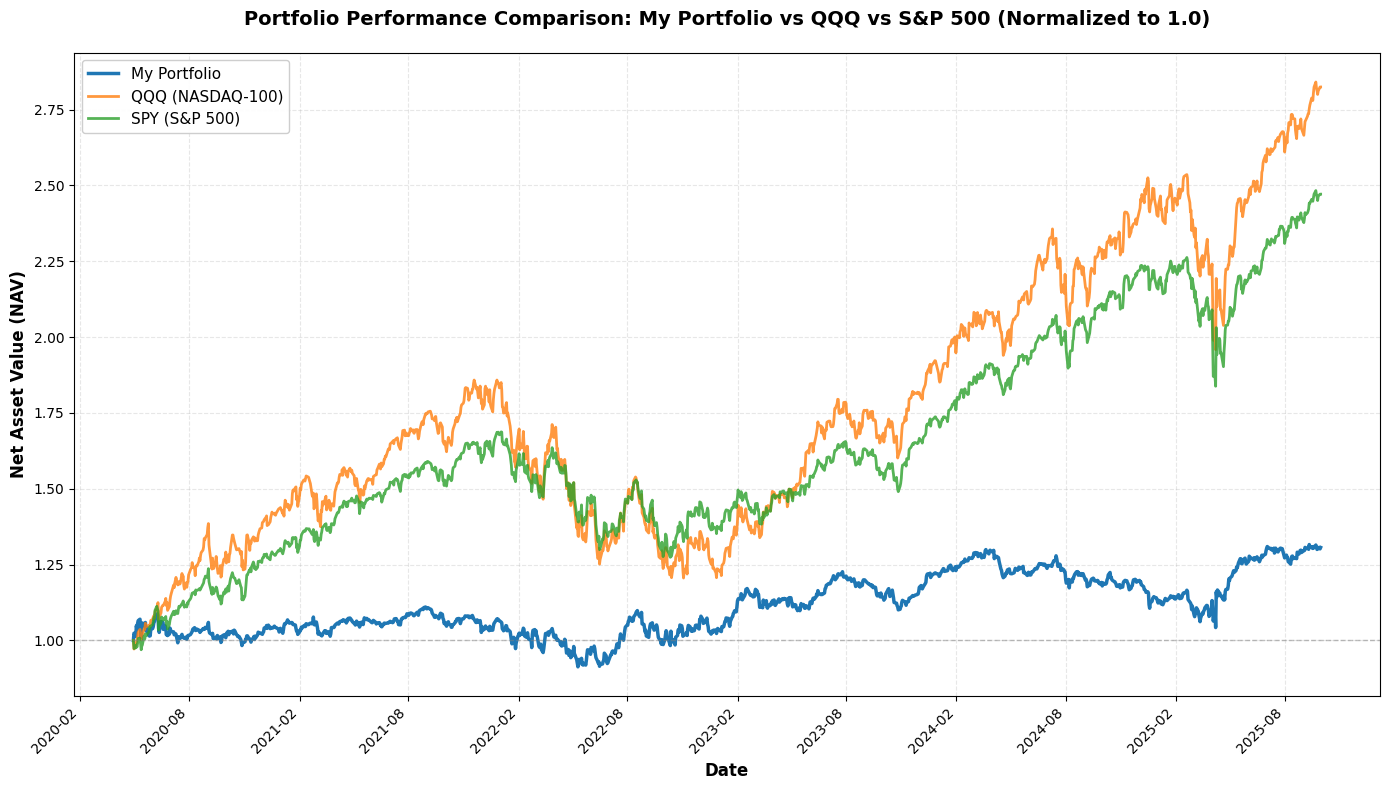

In [ ]:
QQQ = yf.download("QQQ", start=result.index.min(), end=result.index.max(), progress=False, multi_level_index=False)
spy = yf.download("SPY", start=result.index.min(), end=result.index.max(), progress=False, multi_level_index=False)

qqq_nav = QQQ['Close'] / QQQ['Close'].iloc[0]
spy_nav = spy['Close'] / spy['Close'].iloc[0]

comparison_df = pd.DataFrame({
    'Portfolio': result['nav'],
    'QQQ': qqq_nav,
    'SPY': spy_nav
})

comparison_df = comparison_df.ffill()

comparison_df = comparison_df.dropna()

print("Normalizing NAV curves to start from 1.0...")
comparison_df = comparison_df / comparison_df.iloc[0]

print(f"Aligned data shape: {comparison_df.shape}")
print(f"Date range: {comparison_df.index.min()} to {comparison_df.index.max()}")

fig, ax = plt.subplots(figsize=(14, 8))

ax.plot(comparison_df.index, comparison_df['Portfolio'], label='My Portfolio', linewidth=2.5, color='#1f77b4')
ax.plot(comparison_df.index, comparison_df['QQQ'], label='QQQ (NASDAQ-100)', linewidth=2, color='#ff7f0e', alpha=0.8)
ax.plot(comparison_df.index, comparison_df['SPY'], label='SPY (S&P 500)', linewidth=2, color='#2ca02c', alpha=0.8)

ax.axhline(y=1.0, color='gray', linestyle='--', linewidth=1, alpha=0.5)

ax.set_xlabel('Date', fontsize=12, fontweight='bold')
ax.set_ylabel('Net Asset Value (NAV)', fontsize=12, fontweight='bold')
ax.set_title('Portfolio Performance Comparison: My Portfolio vs QQQ vs S&P 500 (Normalized to 1.0)', 
             fontsize=14, fontweight='bold', pad=20)
ax.legend(fontsize=11, loc='best', framealpha=0.95)
ax.grid(True, alpha=0.3, linestyle='--')

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.xticks(rotation=45, ha='right')

ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.2f}'))

plt.tight_layout()

output_file = os.path.join(output_path_step2, 'baseline_comparison_chart.png')
plt.savefig(output_file, dpi=300, bbox_inches='tight')
print(f"Chart saved to: {output_file}")

plt.show()

### 4. Strategy

Backtest 2020-05-01 -> 2025-09-30, fee 0.1% per unit turnover

                                                           Final NAV Cum. return    CAGR Ann. vol Sharpe (rf=0) Max drawdown Avg daily turnover Total cost drag Avg tech weight
Baseline (notebook replica)                                     1.31      30.67%   5.06%   15.15%          0.40      -19.77%             0.0322           4.38%          46.84%
[look-ahead] Course signal, top 25% rank-weighted, monthly      2.56     156.00%  18.96%   20.24%          0.96      -28.94%             0.0192           2.61%          60.37%
Baseline selection, close-to-close, daily rebal                 2.51     151.48%  18.56%   19.75%          0.96      -28.05%             0.0289           3.93%          51.17%
Top 25% EW, monthly rebal                                       2.56     156.13%  18.97%   19.62%          0.99      -28.39%             0.0159           2.16%          51.17%
Top 10% EW, monthly rebal                                

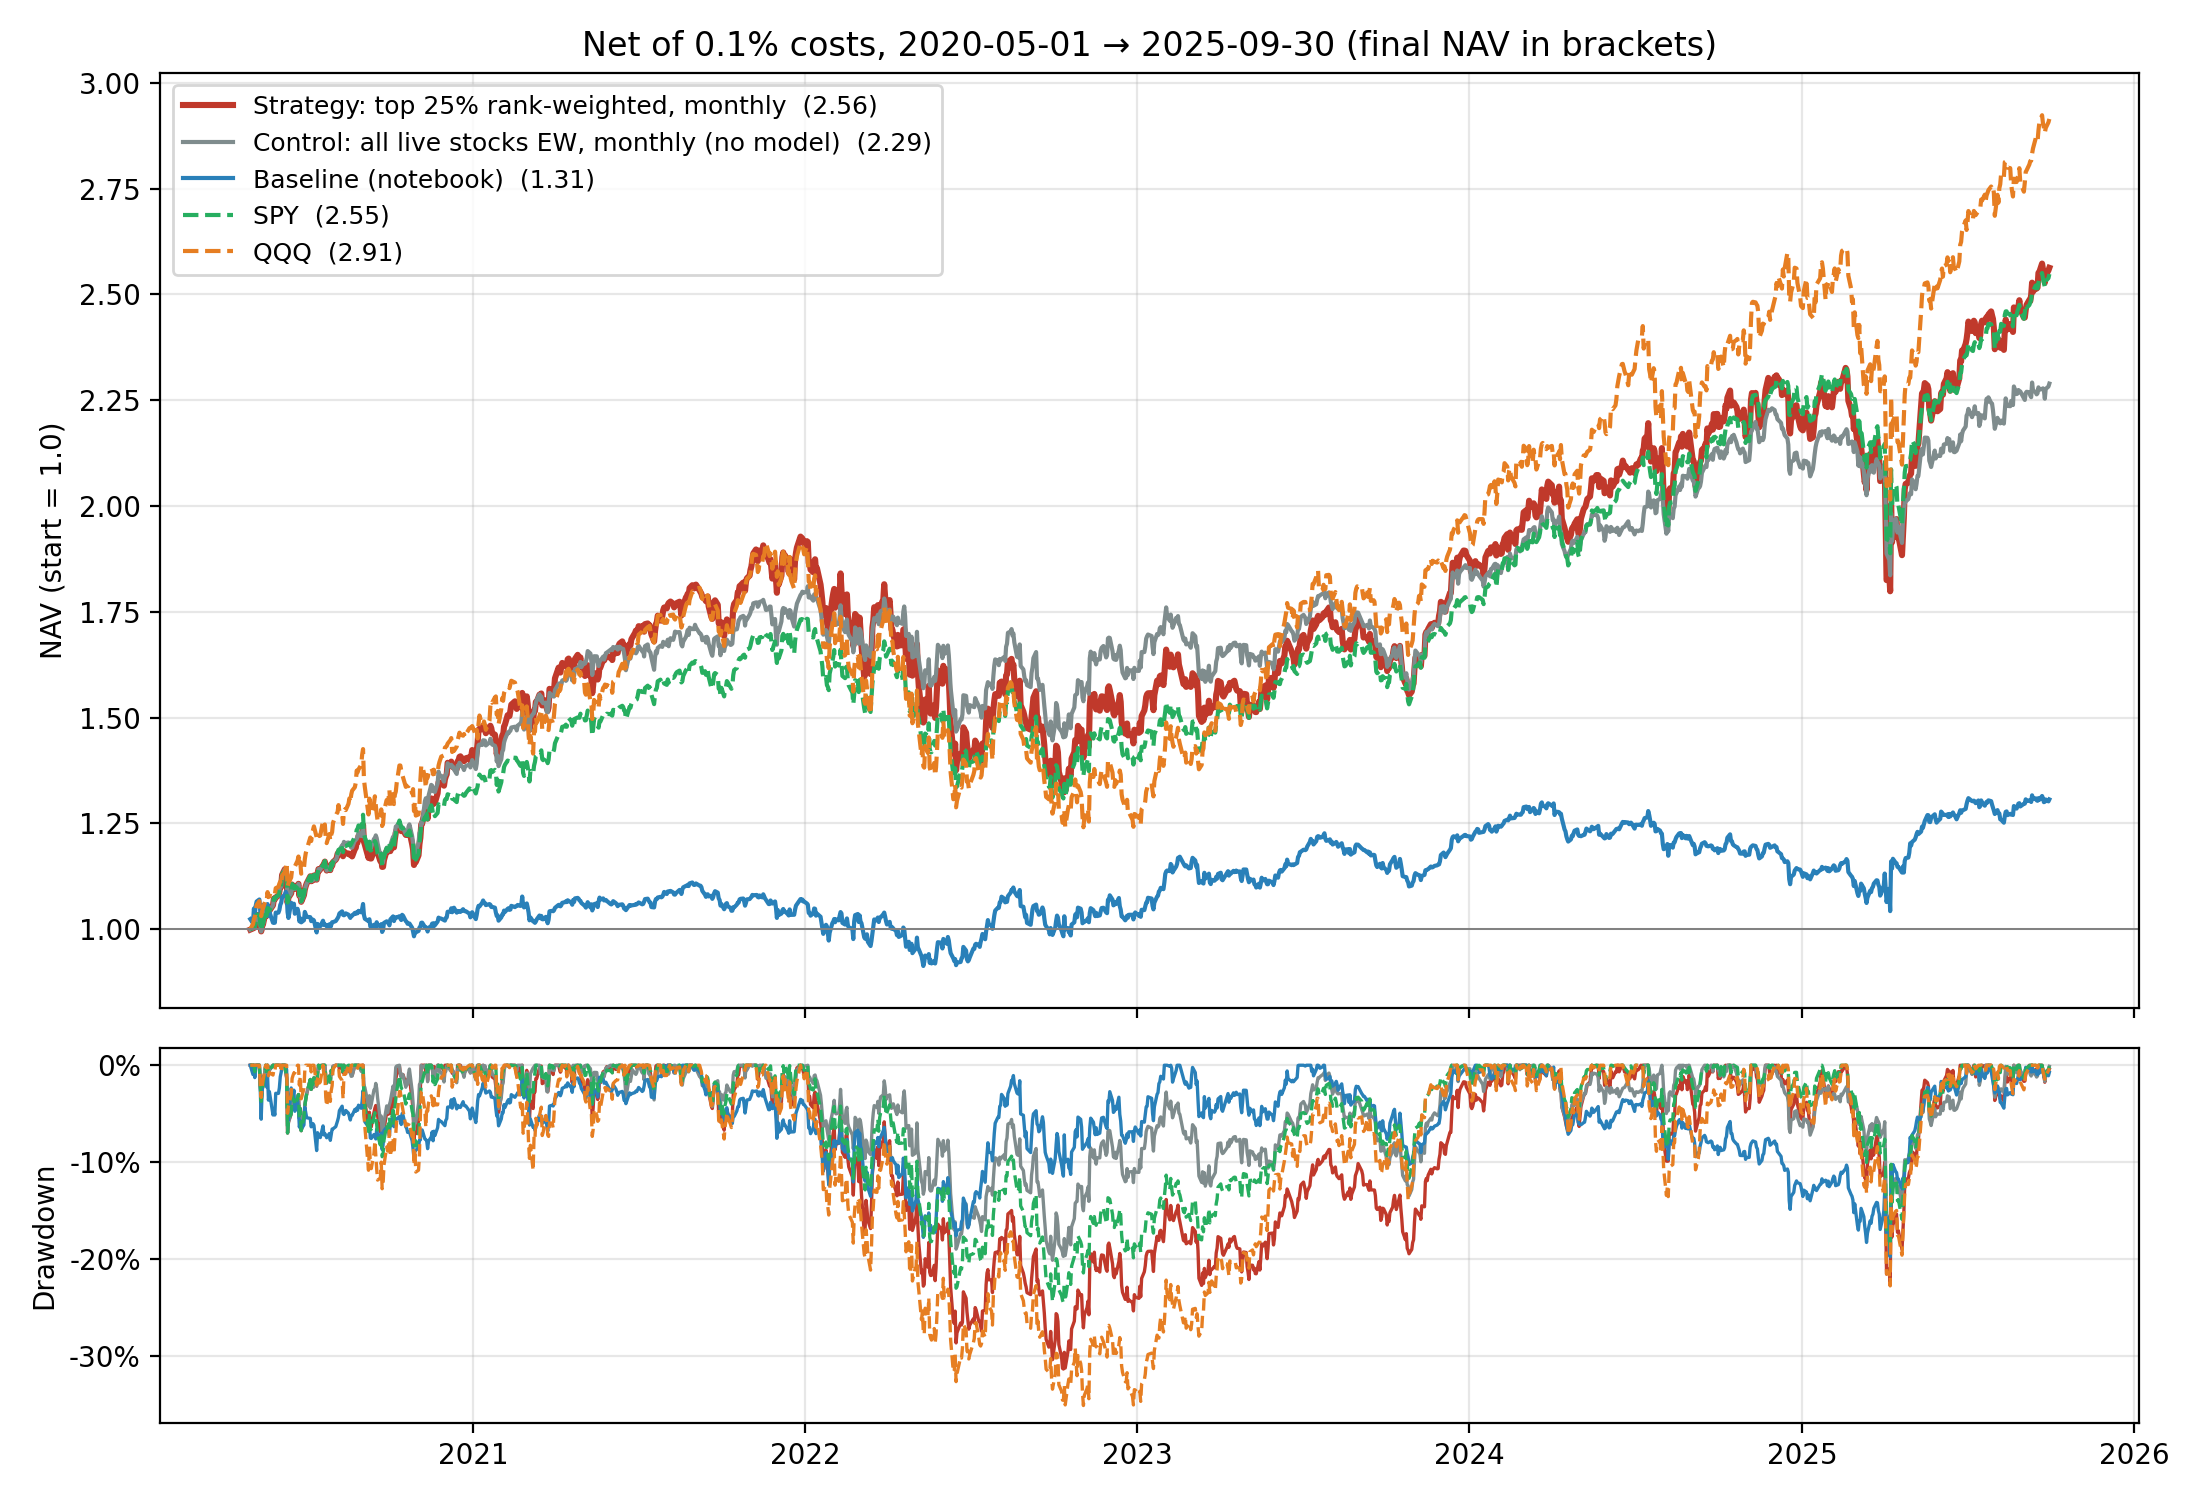

In [ ]:
import subprocess, sys
from IPython.display import Image, display

run = subprocess.run([sys.executable, "strategy_backtest.py"], capture_output=True, text=True)
print(run.stdout[run.stdout.find("Backtest "):])
display(Image("outputs/main_comparison.png"))